# Description

Step 3 of the plan on #733: does the answer of step 2 change with the
market conditions? As GP asked, this only describes what happens, without
a causal analysis (`D17`).

- Same data, models, and trades as `tradability.models.ipynb`: BTC and
  ETH, 5-minute bars, three models, walk forward by year, non-overlapping
  trades in 2022-01-01 to 2026-10-01
- Each trade is labeled with the market conditions at decision time, using
  past data only (`regime_utils.compute_regimes()`):
  - volatility: the 7-day volatility against its terciles over the past
    year: calm, normal, volatile
  - trend: the 7-day return divided by its expected size from the 7-day
    volatility (t-statistic): falling (t < -1), flat, rising (t > 1)
- The models are not refit per regime: the same trades are split by the
  conditions they were made in
- Each PnL per trade comes with its standard error, since some groups are
  small

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import data_utils as dutil
import matplotlib.pyplot as plt
import pandas as pd
import predict_utils as putil
import regime_utils as rutil

## Config

In [2]:
SYMBOLS = ["BTCUSDT", "ETHUSDT"]
INTERVAL = "5m"
START = "2020-01-01"
END = "2026-10-01"
HORIZONS = ["5m", "15m", "1h", "4h", "1d"]
TEST_YEARS = [2022, 2023, 2024, 2025, 2026]
# Costs per round trip, as in the cost sweep of `tradability.models.ipynb`.
COSTS = [0.0, 0.0002, 0.0005, 0.001]
MOMENTUM_COLUMNS = {
    "5m": "ret_1",
    "15m": "ret_3",
    "1h": "ret_12",
    "4h": "ret_48",
    "1d": "mom_1d",
}
MODELS = ["always_buy", "momentum", "logistic"]
REGIME_TYPES = {
    "vol_regime": rutil.VOL_REGIMES,
    "trend_regime": rutil.TREND_REGIMES,
}

## Data, features, labels, regimes

In [3]:
clean = {}
for symbol in SYMBOLS:
    raw = dutil.load_ohlcv(symbol, START, END, interval=INTERVAL)
    clean[symbol] = dutil.clean_bars(raw, interval=INTERVAL)
other = {"BTCUSDT": "ETHUSDT", "ETHUSDT": "BTCUSDT"}
features = {}
labels = {}
regimes = {}
for symbol in SYMBOLS:
    features[symbol] = dutil.compute_features(
        clean[symbol],
        other=clean[other[symbol]],
        other_name=other[symbol][:3].lower(),
        interval=INTERVAL,
    )
    labels[symbol] = dutil.compute_labels(
        clean[symbol], HORIZONS, interval=INTERVAL
    )
    regimes[symbol] = rutil.compute_regimes(features[symbol], interval=INTERVAL)

## How often each regime happens

Share of the bars in 2022-2026.

In [4]:
test_start = f"{TEST_YEARS[0]}-01-01"
rows = []
for symbol in SYMBOLS:
    df = regimes[symbol].loc[test_start:]
    for regime_type, names in REGIME_TYPES.items():
        share = df[regime_type].value_counts(normalize=True)
        for name in names:
            rows.append(
                {
                    "symbol": symbol,
                    "regime_type": regime_type,
                    "regime": name,
                    "share": share[name],
                }
            )
shares = pd.DataFrame(rows).pivot_table(
    index=["regime_type", "regime"], columns="symbol", values="share"
)
shares.round(3)

symbol                 BTCUSDT  ETHUSDT
regime_type  regime                    
trend_regime falling     0.109    0.122
             flat        0.727    0.708
             rising      0.164    0.170
vol_regime   calm        0.422    0.394
             normal      0.301    0.294
             volatile    0.277    0.312

## Predict and evaluate per regime

In [5]:
rows = []
trades = {}
for symbol in SYMBOLS:
    for horizon in HORIZONS:
        pos = {
            "always_buy": putil.predict_always_buy(features[symbol]),
            "momentum": putil.predict_momentum(
                features[symbol], MOMENTUM_COLUMNS[horizon]
            ),
            "logistic": putil.predict_logistic(
                features[symbol],
                labels[symbol],
                horizon,
                TEST_YEARS,
                interval=INTERVAL,
            ),
        }
        # One trade every horizon, in the test years only.
        sample = dutil.sample_non_overlapping(
            labels[symbol], horizon, interval=INTERVAL
        )
        sample = sample[sample.index >= test_start]
        fwd_ret = sample[f"fwd_ret_{horizon}"]
        for model in MODELS:
            trades[(symbol, horizon, model)] = pd.DataFrame(
                {"pos": pos[model].reindex(sample.index), "fwd_ret": fwd_ret}
            )
            for regime_type in REGIME_TYPES:
                stats = putil.evaluate_by_group(
                    pos[model].reindex(sample.index),
                    fwd_ret,
                    regimes[symbol][regime_type].reindex(sample.index),
                )
                stats["symbol"] = symbol
                stats["horizon"] = horizon
                stats["model"] = model
                stats["regime_type"] = regime_type
                rows.append(stats.reset_index(names="regime"))
results = pd.concat(rows, ignore_index=True)
# How many standard errors the PnL per trade is from zero.
results["t_stat"] = results["gross_bps"] / results["se_bps"]
cols = ["symbol", "regime_type", "model", "regime", "horizon"]
results = results.set_index(cols).sort_index()
results[
    ["n", "hit_rate", "weighted_hit_rate", "gross_bps", "se_bps", "t_stat"]
].round(3)

n  hit_rate  \
symbol  regime_type  model      regime   horizon                       
BTCUSDT trend_regime always_buy falling  15m       18043.0     0.499   
                                         1d          191.0     0.534   
                                         1h         4511.0     0.511   
                                         4h         1126.0     0.545   
                                         5m        54016.0     0.500   
...                                                    ...       ...   
ETHUSDT vol_regime   momentum   volatile 15m       51647.0     0.479   
                                         1d          539.0     0.453   
                                         1h        12916.0     0.481   
                                         4h         3234.0     0.471   
                                         5m       154729.0     0.489   

                                                  weighted_hit_rate  \
symbol  regime_type  model      regime   horizon                      
BTCUSDT trend_regime always_buy falling  15m                  0.501   
                                         1d                   0.520   
                                         1h                   0.502   
                                         4h                   0.522   
                                         5m                   0.500   
...                                                             ...   
ETHUSDT vol_regime   momentum   volatile 15m                  0.493   
                                         1d                   0.432   
                                         1h                   0.498   
                                         4h                   0.493   
                                         5m                   0.500   

                                                  gross_bps  se_bps  t_stat  
symbol  regime_type  model      regime   horizon                             
BTCUSDT trend_regime always_buy falling  15m          0.055   0.310   0.179  
                                         1d           9.796  26.920   0.364  
                                         1h           0.205   1.173   0.175  
                                         4h           4.219   4.445   0.949  
                                         5m           0.005   0.104   0.052  
...                                                     ...     ...     ...  
ETHUSDT vol_regime   momentum   volatile 15m         -0.439   0.206  -2.136  
                                         1d         -39.110  17.870  -2.189  
                                         1h          -0.204   0.808  -0.252  
                                         4h          -1.680   3.126  -0.537  
                                         5m           0.003   0.069   0.049  

[180 rows x 6 columns]

## Volatility: PnL per trade of the logistic regression

PnL per trade before costs (bp) and how many standard errors it is from
zero.

In [6]:
idx = pd.IndexSlice
logistic_vol = results.loc[idx[:, "vol_regime", "logistic"], :]
table = logistic_vol[["gross_bps", "se_bps", "t_stat"]].unstack("horizon")
table = table.reindex(columns=HORIZONS, level="horizon")
table = table.droplevel(["regime_type", "model"])
table = table.reindex(rutil.VOL_REGIMES, level="regime")
table.round(2)

gross_bps                           se_bps                    \
horizon                 5m   15m    1h     4h     1d     5m   15m    1h    4h   
symbol  regime                                                                  
BTCUSDT calm         -0.01  0.03 -0.27  -1.36  -4.11   0.03  0.08  0.32  1.32   
        normal        0.03  0.13 -0.46   0.13 -10.75   0.04  0.12  0.47  1.81   
        volatile      0.05  0.55  1.67   7.65  35.35   0.06  0.17  0.65  2.50   
ETHUSDT calm         -0.03 -0.14 -0.86  -3.39  -7.42   0.04  0.11  0.43  1.75   
        normal       -0.05 -0.08 -1.84  -2.67  11.66   0.05  0.16  0.62  2.51   
        volatile     -0.10  0.33  2.21  10.94  28.36   0.07  0.21  0.81  3.12   

                        t_stat                          
horizon              1d     5m   15m    1h    4h    1d  
symbol  regime                                          
BTCUSDT calm       8.52  -0.25  0.31 -0.82 -1.03 -0.48  
        normal    10.90   0.88  1.07 -1.00  0.07 -0.99  
        volatile  14.82   0.92  3.33  2.56  3.06  2.39  
ETHUSDT calm      11.90  -0.94 -1.34 -1.99 -1.94 -0.62  
        normal    15.70  -0.92 -0.50 -2.98 -1.07  0.74  
        volatile  17.91  -1.48  1.62  2.74  3.51  1.58

## Is it one year?

PnL per trade before costs (bp) of the logistic regression in volatile
markets, for each test year.

In [7]:
rows = []
for symbol in SYMBOLS:
    for horizon in HORIZONS:
        df = trades[(symbol, horizon, "logistic")]
        vol_regime = regimes[symbol]["vol_regime"].reindex(df.index)
        df = df[vol_regime == "volatile"]
        stats = putil.evaluate_by_group(
            df["pos"], df["fwd_ret"], pd.Series(df.index.year, index=df.index)
        )
        stats["symbol"] = symbol
        stats["horizon"] = horizon
        rows.append(stats.reset_index(names="year"))
by_year = pd.concat(rows, ignore_index=True)
by_year = by_year.pivot_table(
    index=["symbol", "year"], columns="horizon", values="gross_bps"
)[HORIZONS]
by_year.round(2)

horizon         5m   15m    1h     4h     1d
symbol  year                                
BTCUSDT 2022 -0.06  1.03  5.45  13.41   7.86
        2023  0.27  0.76  1.55  12.26  60.69
        2024  0.04  0.48  1.55   7.95  55.27
        2025 -0.01  0.48 -1.21   5.39  38.91
        2026  0.09  0.20  1.88   1.37   1.12
ETHUSDT 2022 -0.04  1.07  5.23  15.93  37.06
        2023  0.19  0.28  0.13   4.98 -13.58
        2024 -0.21  0.24  2.69   8.70  45.14
        2025 -0.19  0.00 -0.26  16.27  29.47
        2026  0.22  0.12  3.10  -2.53 -25.99

## Weighted hit rate per regime

Share of the total |r| traded in the right direction. The PnL before costs
is positive only above 0.5. Bars: 2 standard errors. The PnL per trade is
(2 * whr - 1) * mean |r|, so the standard error of the weighted hit rate is
se / (2 * mean |r|).

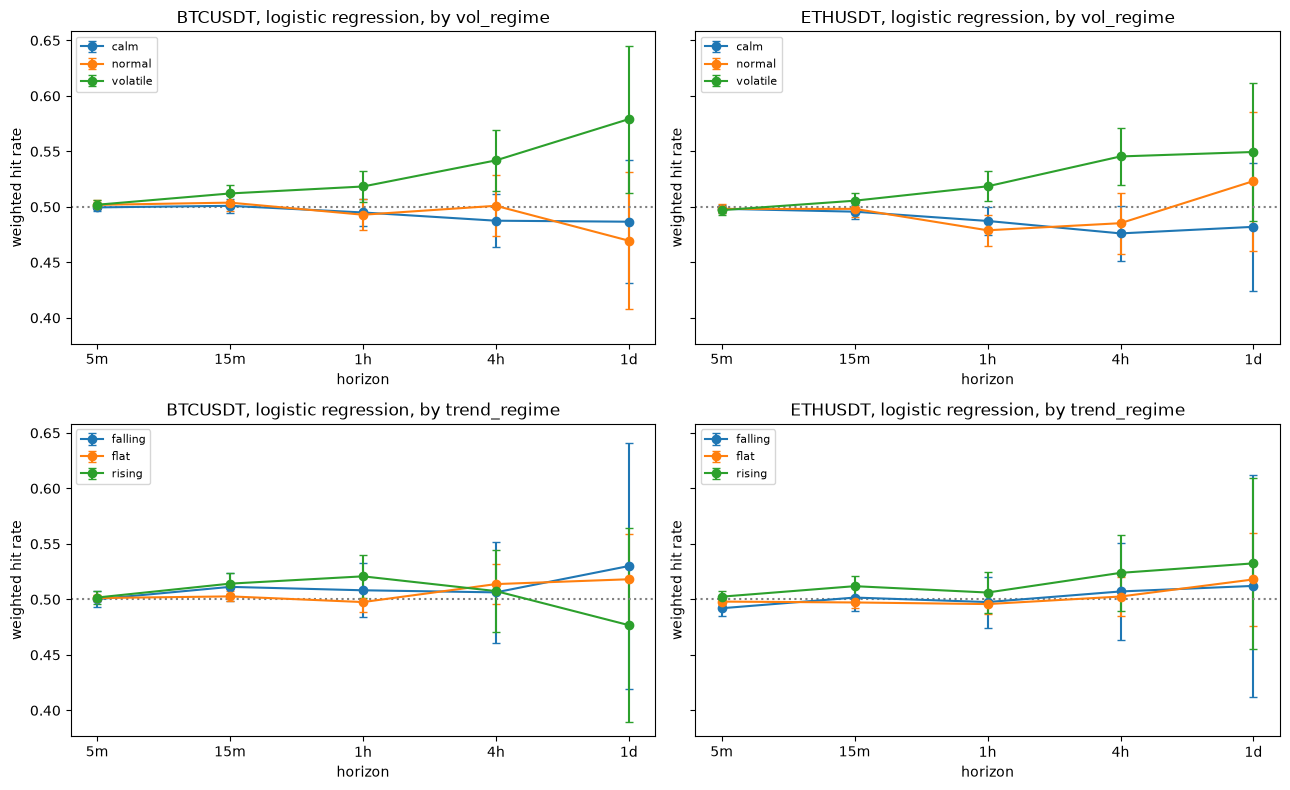

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for row, regime_type in enumerate(REGIME_TYPES):
    for col, symbol in enumerate(SYMBOLS):
        ax = axes[row, col]
        for i, regime in enumerate(REGIME_TYPES[regime_type]):
            sub = results.loc[idx[symbol, regime_type, "logistic", regime], :]
            sub = sub.reindex(HORIZONS)
            err = 2 * sub["se_bps"] / (2 * sub["mean_abs_bps"])
            ax.errorbar(
                HORIZONS,
                sub["weighted_hit_rate"],
                yerr=err,
                marker="o",
                capsize=3,
                color=f"C{i}",
                label=regime,
            )
        ax.axhline(0.5, color="gray", linestyle=":")
        ax.set_title(f"{symbol}, logistic regression, by {regime_type}")
        ax.set_xlabel("horizon")
        ax.set_ylabel("weighted hit rate")
        ax.legend(fontsize=8)
plt.tight_layout()

## Best horizon per regime and cost

For each regime and cost, the model and horizon with the highest PnL per
trade after costs, and how many standard errors its PnL before costs is
from zero. A negative net PnL means nothing makes money in that regime at
that cost.

In [9]:
# The best model and horizon is the one with the highest PnL before costs,
# since the cost is the same for every trade.
flat = results.reset_index()
keys = ["symbol", "regime_type", "regime"]
best_rows = flat.groupby(keys, observed=True)["gross_bps"].idxmax()
best = flat.loc[best_rows].set_index(keys)
best = best[["model", "horizon", "gross_bps", "t_stat"]]
for cost in COSTS:
    best[f"net_bps at {cost * 1e4:g} bp"] = best["gross_bps"] - cost * 1e4
best.round(2)

model horizon  gross_bps  t_stat  \
symbol  regime_type  regime                                            
BTCUSDT trend_regime falling     logistic      1d      14.63    0.54   
                     flat        logistic      1d       6.19    0.89   
                     rising    always_buy      1d      27.16    1.77   
        vol_regime   calm        momentum      1d      19.13    2.25   
                     normal      momentum      1d       9.65    0.88   
                     volatile    logistic      1d      35.35    2.39   
ETHUSDT trend_regime falling     logistic      1d       8.57    0.24   
                     flat        logistic      1d       8.34    0.85   
                     rising    always_buy      1d      27.59    1.63   
        vol_regime   calm        momentum      1d      13.28    1.12   
                     normal    always_buy      1d      15.30    0.97   
                     volatile    logistic      1d      28.36    1.58   

                               net_bps at 0 bp  net_bps at 2 bp  \
symbol  regime_type  regime                                       
BTCUSDT trend_regime falling             14.63            12.63   
                     flat                 6.19             4.19   
                     rising              27.16            25.16   
        vol_regime   calm                19.13            17.13   
                     normal               9.65             7.65   
                     volatile            35.35            33.35   
ETHUSDT trend_regime falling              8.57             6.57   
                     flat                 8.34             6.34   
                     rising              27.59            25.59   
        vol_regime   calm                13.28            11.28   
                     normal              15.30            13.30   
                     volatile            28.36            26.36   

                               net_bps at 5 bp  net_bps at 10 bp  
symbol  regime_type  regime                                       
BTCUSDT trend_regime falling              9.63              4.63  
                     flat                 1.19             -3.81  
                     rising              22.16             17.16  
        vol_regime   calm                14.13              9.13  
                     normal               4.65             -0.35  
                     volatile            30.35             25.35  
ETHUSDT trend_regime falling              3.57             -1.43  
                     flat                 3.34             -1.66  
                     rising              22.59             17.59  
        vol_regime   calm                 8.28              3.28  
                     normal              10.30              5.30  
                     volatile            23.36             18.36

## Trend: always buy and the logistic regression

PnL per trade before costs (bp) by trend regime, and its t-statistic.

In [10]:
trend = results.loc[idx[:, "trend_regime", ["always_buy", "logistic"]], :]
table = trend[["gross_bps", "t_stat"]].unstack("horizon")
table = table.reindex(columns=HORIZONS, level="horizon")
table = table.droplevel("regime_type")
table.round(2)

gross_bps                          t_stat        \
horizon                           5m   15m    1h    4h     1d     5m   15m   
symbol  model      regime                                                    
BTCUSDT always_buy falling      0.01  0.06  0.21  4.22   9.80   0.05  0.18   
                   flat         0.01  0.03  0.14  0.08   1.85   0.45  0.41   
                   rising       0.10  0.28  0.99  3.73  27.16   1.76  1.66   
        logistic   falling      0.00  0.55  0.79  1.24  14.63   0.05  1.78   
                   flat         0.02  0.08 -0.15  1.76   6.19   0.91  1.18   
                   rising       0.03  0.49  1.42  1.02  -8.23   0.61  2.96   
ETHUSDT always_buy falling      0.12  0.31  1.06  4.25   1.86   0.88  0.79   
                   flat        -0.04 -0.13 -0.40 -1.87  -0.59  -1.38 -1.39   
                   rising       0.19  0.59  1.97  8.78  27.59   2.71  2.82   
        logistic   falling     -0.30  0.11 -0.32  1.91   8.57  -2.31  0.28   
                   flat        -0.05 -0.11 -0.35  0.44   8.34  -1.49 -1.20   
                   rising       0.06  0.54  0.56  4.41  14.30   0.93  2.57   

                                              
horizon                       1h    4h    1d  
symbol  model      regime                     
BTCUSDT always_buy falling  0.17  0.95  0.36  
                   flat     0.49  0.07  0.27  
                   rising   1.51  1.48  1.77  
        logistic   falling  0.68  0.28  0.54  
                   flat    -0.53  1.55  0.89  
                   rising   2.17  0.41 -0.53  
ETHUSDT always_buy falling  0.70  0.73  0.05  
                   flat    -1.06 -1.22 -0.06  
                   rising   2.39  2.76  1.63  
        logistic   falling -0.21  0.33  0.24  
                   flat    -0.92  0.29  0.85  
                   rising   0.67  1.38  0.84

## Observations

How often:
- In 2022-2026 the market was calm about 40% of the time, normal 30%, and
  volatile 30% (the thresholds come from the past year, and 2022-2026 was
  calmer than 2020-2021). It was flat 71-73% of the time, rising 16-17%,
  falling 11-12%

Volatility:
- The logistic regression's edge is in volatile markets only. There its
  weighted hit rate goes up with the horizon, from 0.50 at 5m to 0.54 at
  4h and 0.55-0.58 at 1d. In calm and normal markets it stays at about
  0.50 or below (the one exception, ETH at 1d in normal markets with 0.52,
  is within its error), and the model loses a little at most horizons
- In volatile markets the PnL per trade before costs is 1.7 bp (BTC) and
  2.2 bp (ETH) at 1h, 7.7 and 10.9 bp at 4h, and 35 and 28 bp at 1d. From
  1h to 4h it is 2.6 to 3.5 standard errors from zero on both coins
- So the step 2 average (0-2 bp, nothing after costs) hides two different
  markets: no edge in calm and normal times, and an edge that grows with
  the horizon in volatile times
- It is not one lucky year: at 4h the volatile-market PnL is positive in 9
  of the 10 coin-years, but it gets smaller over time, and in 2026 it is
  1.4 bp (BTC) and -2.5 bp (ETH)
- With costs: at 4h in volatile markets the PnL per trade (7.7-10.9 bp) is
  about the 10 bp cost, so it would pay a cost of 5 bp. At 1d it is above
  10 bp, but on only about 500 trades per coin, so the uncertainty is
  large (BTC 35 +/- 15 bp, ETH 28 +/- 18 bp)
- Always buying does not show the same pattern (at most 1.5 standard
  errors), so the edge comes from the model, not from the market going up
  more in volatile times

Trend:
- The trend splits show much less. Always buying after a rising week makes
  a little more at every horizon (ETH: 2.4-2.8 standard errors from 5m to
  4h; BTC: 1.5-1.8), so a weekly up move tends to continue a bit
- Short moves reverse in every regime: momentum at 15m loses in all of
  them, the most in flat markets (BTC: 5.8 standard errors)

Best horizon:
- In every regime the highest PnL per trade is at 1d, since that is where
  the moves are largest. But the 1d results are noisy: none is more than
  2.4 standard errors from zero. The volatile-market edge is clearer from
  1h to 4h, where there are many more trades

Caveats:
- Each regime type splits the trades into 90 groups (2 coins, 5 horizons,
  3 models, 3 regimes). At 2 standard errors, about 5 would look
  significant by chance. The volatile-market result holds on both coins
  and at 4 horizons, so it is unlikely to be chance, but it should be
  checked on new data
- The regime definitions (terciles over the past year, |t| > 1) were set
  once and not tuned